In [1]:
import numpy as np
import joblib
import importlib
import matplotlib.pyplot as plt
import os 
import pickle
import bayes_logistic as bl
from collections import defaultdict
import warnings
warnings.filterwarnings("ignore")
from tqdm import trange, tqdm

os.chdir('/Users/eochoa/Documents/Research_Abuj/ASD/Code/')

import pandas as pd
from utils import *
from linear_utils import *
from logistic_utils import *
#from GP_utils import *
from linear_utils import *
import expt_utils as expt_utils
from sklearn.preprocessing import normalize
from sklearn.datasets import load_iris
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.mixture import GaussianMixture
from sklearn.mixture import BayesianGaussianMixture
from scipy.special import expit, logit
import sklearn
import seaborn as sns
# importlib.reload(expt_utils)
from sklearn.neighbors import NearestNeighbors

from sklearn.metrics import pairwise_distances

from scipy.stats import multivariate_normal

In [2]:
def gen_data():
    n_mix = 4
    S_list = []
    rv_list = []
    size_list = [600,200,150,50]
    mean_list = [[5,5],[-5,-5],[-5,5],[5,-5]]
    sigma_list = [1.7,1.8,1.5,1.7]

    for i in range(n_mix):
        mui = mean_list[i]
        sigmai = sigma_list[i]*np.eye(2)
        Si = np.random.multivariate_normal(mui, sigmai, size_list[i])
        rvi = multivariate_normal(mean=mui, cov=sigmai) 
        pdfi = rvi.pdf(Si)
        #Si = np.concatenate([Si, i*np.ones((size_list[i],1)), pdfi.reshape((size_list[i],1))], axis=1)
        rv_list.append(rvi)
        S_list.append(Si)

    x = np.concatenate(S_list)

    N = 1000
    p = 2
    theta = 5*np.random.rand(p+1)
    expit = lambda x: 1/(1+np.exp(-x))
    #x = np.random.multivariate_normal(np.zeros(p),np.eye(p)+np.ones((p,p))*.5,N)
    x_ = np.concatenate([np.ones((N,1)), x],axis=1)
    #f = x @ theta
    #p = expit(f) 
    y = x_ @ theta +  np.random.normal(size=N)#np.random.binomial(1,p)
    #plt.scatter(x[:,0], x[:,1], c=y)
    return x, y, theta

In [3]:
def gen_data(N=1000):

    #N = 10000
    p = 2
    theta = 5*np.random.rand(p+1)
    expit = lambda x: 1/(1+np.exp(-x))
    x = np.random.multivariate_normal(np.zeros(p),2*(np.eye(p)+np.ones((p,p))*.5),N)
    x_ = np.concatenate([np.ones((N,1)), x],axis=1)
    #f = x @ theta
    #p = expit(f) 
    y = x_ @ theta +  np.random.normal(size=N)#np.random.binomial(1,p)
    #plt.scatter(x[:,0], x[:,1], c=y)
    return x, y, theta

In [4]:
import math
def gen_data():
    E = np.random.exponential(1,1000)
    Theta = np.random.rand(1000) * 2 * math.pi
    Gamma = np.sqrt(E.cumsum()) / (math.pi)
    x = np.array([np.cos(Theta) * Gamma, np.sin(Theta) * Gamma]).T

    #x = np.concatenate(S_list)

    N = 1000
    p = 2
    theta = np.concatenate([np.zeros(1), 5*np.random.rand(p)])#5*np.random.rand(p+1)
    expit = lambda x: 1/(1+np.exp(-x))
    #x = np.random.multivariate_normal(np.zeros(p),np.eye(p)+np.ones((p,p))*.5,N)
    x_ = np.concatenate([np.ones((N,1)), x],axis=1)
    #f = x @ theta
    #p = expit(f) 
    y = x_ @ theta +  np.random.normal(size=N)#np.random.binomial(1,p)
    #plt.scatter(x[:,0], x[:,1], c=y)
    return x, y, theta

In [5]:
def gen_data(N=1000):

    #N = 10000
    p = 2
    theta = np.concatenate([np.zeros(1), 5*np.random.rand(p)])#5*np.random.rand(p+1)
    expit = lambda x: 1/(1+np.exp(-x))
    x = np.random.rand(p*N).reshape(N, p)
    x_ = np.concatenate([np.ones((N,1)), x],axis=1)
    #f = x @ theta
    #p = expit(f) 
    y = x_ @ theta +  np.random.normal(size=N)#np.random.binomial(1,p)
    #plt.scatter(x[:,0], x[:,1], c=y)
    return x, y, theta

In [15]:
def gen_data(N=100):

    #N = 10000
    p = 50
    theta = np.concatenate([np.zeros(1), 5*np.random.rand(p)])#5*np.random.rand(p+1)
    r = np.random.rand(N).reshape(N, 1)-1
    x = np.random.rand(N,p).reshape(N, p)
    x = x - x.mean(0)
    x = r*normalize(x, axis=1, norm='l2')
    #x = np.random.rand(p*N).reshape(N, p)
    x_ = np.concatenate([np.ones((N,1)), x],axis=1)
    #x_[:,1] = np.cos(x_[:,1])*x_[:,1] 
    #x_[:,2] = np.sin(x_[:,1])*x_[:,2]
    y = x_ @ theta +  np.random.normal(size=N)#np.random.binomial(1,p)
    return x, y, theta

In [16]:
x, y, theta = gen_data()
#y = np.sin(y)

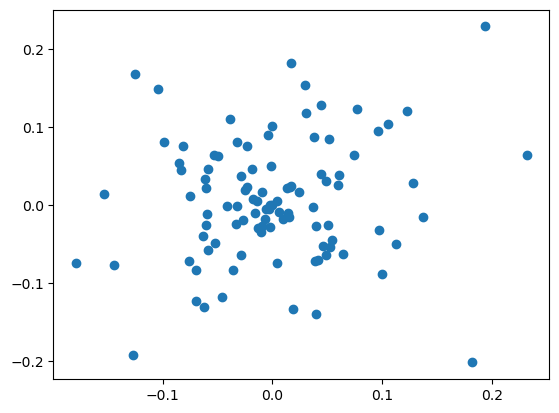

In [18]:
plt.scatter(x[:,5], x[:,1])
#plt.xlim((-4,4))
#plt.ylim((-4,4))

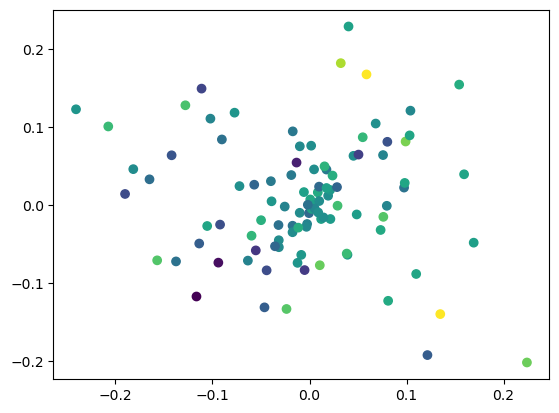

In [24]:
y_ = x @ theta[1:]
#theta_ort = np.array([-theta[1:][1],theta[1:][0]])
#theta_ort_span = np.linspace(-1,1,100).reshape((100,1)) * theta_ort + x[y_.argsort()[::-1][(20-1):20],:]
#x = x - x.mean(0)
#x = normalize(x, axis=1, norm='l2')
plt.scatter(x[:,0], x[:,1], c=y)

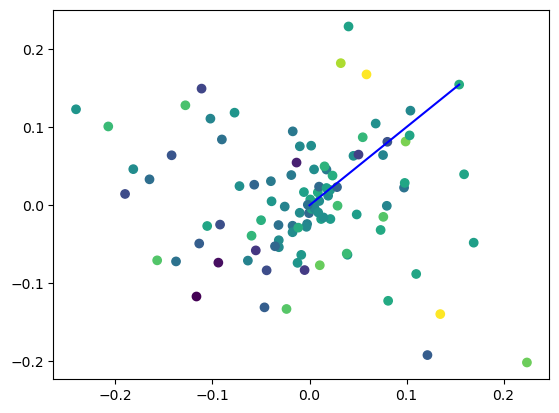

In [27]:
plt.scatter(x[:,0], x[:,1], c=y)

#plt.plot(np.concatenate([np.zeros((1,1)), theta[1].reshape(1,1)], axis=0),
#np.concatenate([np.zeros((1,1)), theta[2].reshape(1,1)], axis=0),c='r')

plt.plot(np.concatenate([np.zeros((1,1)), x[y.argsort()[::-1][(20-1):20],0].reshape(1,1)], axis=0),
np.concatenate([np.zeros((1,1)), x[y.argsort()[::-1][(20-1):20],1].reshape(1,1)], axis=0),c='b')

#plt.plot(np.concatenate([np.zeros((1,1)), x[y.argsort()[::-1][(20-2):(20-1)],0].reshape(1,1)], axis=0),
#np.concatenate([np.zeros((1,1)), x[y.argsort()[::-1][(20-2):(20-1)],1].reshape(1,1)], axis=0),c='b')

#plt.plot(theta_ort_span[:,0],theta_ort_span[:,1])

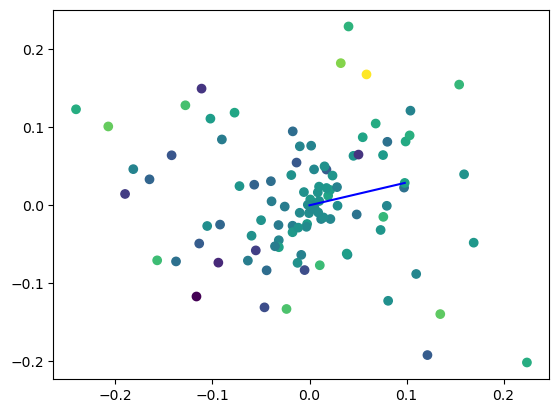

In [31]:
plt.scatter(x[:,0], x[:,1], c=x @ theta[1:])

#plt.scatter(theta[1], theta[2],c='r')
#plt.plot(np.zeros((1,2)), theta[1:].reshape(1,2), c='r')

#plt.plot(np.concatenate([np.zeros((1,1)), theta[1].reshape(1,1)], axis=0),
#np.concatenate([np.zeros((1,1)), theta[2].reshape(1,1)], axis=0),c='r')

plt.plot(np.concatenate([np.zeros((1,1)), x[y_.argsort()[::-1][(20-1):20],0].reshape(1,1)], axis=0),
np.concatenate([np.zeros((1,1)), x[y_.argsort()[::-1][(20-1):20],1].reshape(1,1)], axis=0),c='b')

#plt.plot(np.concatenate([np.zeros((1,1)), x[y.argsort()[::-1][(20-2):(20-1)],0].reshape(1,1)], axis=0),
#np.concatenate([np.zeros((1,1)), x[y.argsort()[::-1][(20-2):(20-1)],1].reshape(1,1)], axis=0),c='b')

#plt.plot(theta_ort_span[:,0],theta_ort_span[:,1])

In [34]:
algos_dict = {
  'Random': [linear_solver, {}, 10, 'Random', 'y'],
  'TS_linear': [TS_linear, {}, 10, 'TS_linear', 'darkblue'],
  #'TS_linear_3': [TS_linear_3, {'gamma':.5}, 10, 'TS_linear_3', 'green'],
  'Greedy_linear': [Greedy_linear, {}, 10, 'Greedy_linear', 'red'],
  #'Greedy_linear_ep': [Greedy_linear, {'epsilon':0.1}, 10, 'Greedy_linear_ep', 'orange'],
    'IDS_linear': [IDS_linear, {}, 10, 'IDS_linear', 'green']
    #'Greedy_GP': [Greedy_GP, {}, 10, 'Greedy_GP', 'm'],
    #'TS_GP': [TS_GP, {}, 10, 'TS_GP', 'm']
    
}

In [50]:
res_sim = defaultdict(list)
for i in trange(10):
    x, y, _ = gen_data()
    #y = np.cos(y) * y 
    n_row, n_col = y.shape[0], 1
    _, n_desc =  x.shape
    cutoff = n_desc
    #T = n_row
    T = 50
    prob_dict = {
        "m": n_row,
        "noise": 0.01,
        "d": cutoff
      }
    prob = linear_discover(**prob_dict)
    x = x - x.mean(0)
    x = normalize(x, axis=0, norm='l2')
    prob.x = x.copy()
    prob.y = y.copy()

    reg_list = {algo:[] for algo in algos_dict}
    #tau_list = {algo:[] for algo in algos_dict}

    for trial_idx in range(5):
        t_prob = deepcopy(prob)
            # print(prob.x)
        for algo, algo_setup in algos_dict.items():
            algo_func, algo_params, algo_N_trials, _, _ = algo_setup
                        # print(algo_func)
            if not trial_idx < algo_N_trials:
                continue
            solver = algo_func(t_prob, **algo_params)
            reg, _ = solver.run(T)[:2]
                #act_list[algo].append(getattr(solver, "logistic_discover"))
                #act_list[algo].append(t_prob.actions)
                # print(prob.rewards)
            reg_list[algo].append(reg)
                #tau_list[algo].append(tau)

        #for algo in algos_dict:
        #algo_label = algos_dict[algo][3]
        #algo_style = algos_dict[algo][4]
    y_1 = np.mean(reg_list['Random'], axis = 0)[:T]
    y_2 = np.mean(reg_list['TS_linear'], axis = 0)[:T]
    y_3 = np.mean(reg_list['Greedy_linear'], axis = 0)[:T]
    #y_4 = np.mean(reg_list['Greedy_linear_ep'], axis = 0)[:T]
    #y_5 = np.mean(reg_list['IDS_linear'], axis = 0)[:T]
    #y_6 = np.mean(reg_list['Greedy_GP'], axis = 0)[:T]
    #y_7 = np.mean(reg_list['TS_GP'], axis = 0)[:T]
    #y_ = y_3 - y_1
    #y_ = y_2 - y_1
            #ci = np.std(reg_list[algo], axis = 0)[:T]
    #plt.plot(range(T), y_, c='b', alpha=.1)
    res_sim['Random'].append(y_1.max())
    res_sim['TS_linear'].append(y_2.max())
    res_sim['Greedy_linear'].append(y_3.max())
    #res_sim['Greedy_linear_ep'].append(y_4.max())
    #res_sim['IDS_linear'].append(y_5.max())
    #res_sim['Greedy_GP'].append(y_6.max())
    #res_sim['TS_GP'].append(y_7.max())
    #plt.plot(range(T), y_1, c='r', alpha=.1)
    #plt.plot(range(T),y_2, c='b', alpha=.1)
        #                  algo_style, label=algo_label, alpha=.1)
            #plt.fill_between(range(T), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

            #plt.legend()

100%|███████████████████████████████████████████| 10/10 [00:26<00:00,  2.63s/it]


<AxesSubplot: >

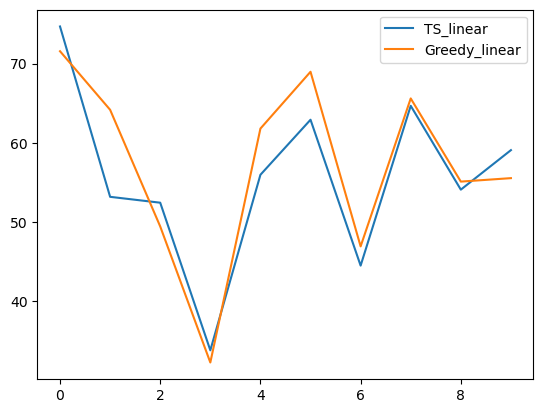

In [51]:
pd.DataFrame(res_sim).iloc[:,1:].plot()

In [52]:
pd.DataFrame(res_sim).mean()

Random           71.805469
TS_linear        55.521956
Greedy_linear    57.128635
dtype: float64

In [53]:


reg_list = {algo:[] for algo in algos_dict}
    #tau_list = {algo:[] for algo in algos_dict}
T=100
for trial_idx in trange(20):
    t_prob = deepcopy(prob)
            # print(prob.x)
    for algo, algo_setup in algos_dict.items():
        algo_func, algo_params, algo_N_trials, _, _ = algo_setup
                        # print(algo_func)
        if not trial_idx < algo_N_trials:
            continue
        solver = algo_func(t_prob, **algo_params)
        reg, _ = solver.run(T)[:2]
                #act_list[algo].append(getattr(solver, "logistic_discover"))
                #act_list[algo].append(t_prob.actions)
                # print(prob.rewards)
        reg_list[algo].append(reg)
                #tau_list[algo].append(tau)

        #for algo in algos_dict:
        #algo_label = algos_dict[algo][3]
        #algo_style = algos_dict[algo][4]

100%|███████████████████████████████████████████| 20/20 [00:10<00:00,  1.92it/s]


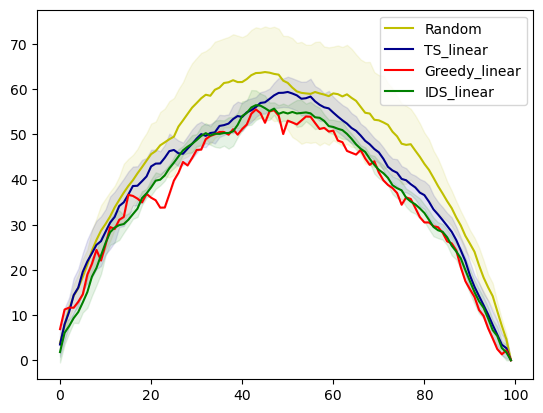

In [54]:
for algo in algos_dict:
    algo_label = algos_dict[algo][3]
    algo_style = algos_dict[algo][4]
    y_ = np.mean(reg_list[algo], axis = 0)[:T]
    ci = np.std(reg_list[algo], axis = 0)[:T]
    plt.plot(range(T), y_,
                  algo_style, label=algo_label)
    plt.fill_between(range(T), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

    plt.legend()

In [46]:
x, y, theta = gen_data()
y_ = (x @ theta[1:])
y_max = (x @ theta[1:])
y_max[::-1].sort()
n_row, n_col = y.shape[0], 1
_, n_desc =  x.shape
cutoff = n_desc
    #T = n_row
prob_dict = {
        "m": n_row,
        "noise": 0.01,
        "d": cutoff
      }
prob = linear_discover(**prob_dict)
x = x - x.mean(0)
x = normalize(x, axis=0, norm='l2')
prob.x = x.copy()
prob.y = y.copy()

    
T = 100
act_list = defaultdict(list)
reg_list = defaultdict(list)
reg1_list = defaultdict(list)
for i in trange(10):
    t_prob = deepcopy(prob)
    solver = Greedy_linear(t_prob, **algo_params) 
    reg, act = solver.run(T)[:2]

    reg_list['Greedy_linear'].append((y_max - y_[solver.prob.actions]).cumsum())
    reg1_list['Greedy_linear'].append(reg)
    act_list['Greedy_linear'].append(solver.prob.actions)
    
    t_prob = deepcopy(prob)
    solver = TS_linear(t_prob, **algo_params)
    reg, act = solver.run(T)[:2]
    
    reg_list['TS_linear'].append((y_max - y_[solver.prob.actions]).cumsum())
    reg1_list['TS_linear'].append(reg)
    act_list['TS_linear'].append(solver.prob.actions)
    
    #t_prob = deepcopy(prob)
    #solver = IDS_linear(t_prob, **algo_params)
    #reg, act = solver.run(T)[:2]
    
    #reg_list['IDS_linear'].append((y_max - y_[solver.prob.actions]).cumsum())
    #reg1_list['IDS_linear'].append(reg)
    #act_list['IDS_linear'].append(solver.prob.actions)
    
    #plt.plot(np.diff((y_max - y_[solver.prob.actions]).cumsum(),0), c='b', alpha=.1)
    #plt.plot(reg, c='r', alpha=.1)

100%|███████████████████████████████████████████| 10/10 [00:01<00:00,  5.99it/s]


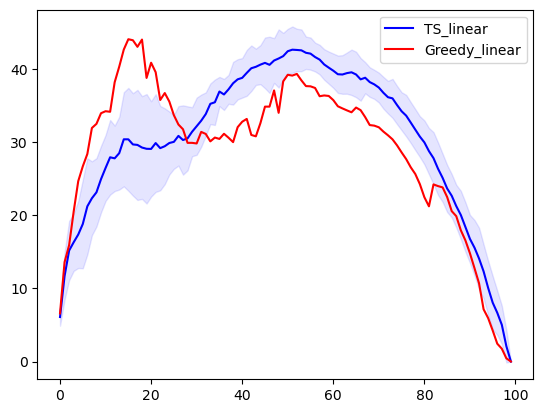

In [47]:
_ = plt.plot(((np.array(reg_list['TS_linear'])).T).mean(1), label='TS_linear', c='b')
_ = plt.fill_between(range(T), (((np.array(reg_list['TS_linear'])).T).mean(1)-((np.array(reg_list['TS_linear'])).T).std(1)), 
                     (((np.array(reg_list['TS_linear'])).T).mean(1)+((np.array(reg_list['TS_linear'])).T).std(1)), 
                     color='b', alpha=.1)

#_ = plt.plot(((np.array(reg_list['IDS_linear'])).T).mean(1), label='IDS_linear', c='y')
#_ = plt.fill_between(range(T), (((np.array(reg_list['IDS_linear'])).T).mean(1)-((np.array(reg_list['IDS_linear'])).T).std(1)), 
#                     (((np.array(reg_list['IDS_linear'])).T).mean(1)+((np.array(reg_list['IDS_linear'])).T).std(1)), 
#                     color='y', alpha=.1)

_ = plt.plot((np.array(reg_list['Greedy_linear'])).T.mean(1), label='Greedy_linear',color='r')
_ = plt.legend()

In [257]:
#np.argsort(y_)[::-1]
#np.array(act_list['Greedy_linear'])[0,1:2] 
#np.argsort(y_)[::-1][:10]

In [321]:
T = 1000
act_list = defaultdict(list)
reg_list = defaultdict(list)
reg1_list = defaultdict(list)
y_list = []

for i in trange(10):
    x, y, theta = gen_data()
    y_ = (x @ theta[1:])
    y_list.append(y_)
    y_max = (x @ theta[1:])
    y_max[::-1].sort()
    n_row, n_col = y.shape[0], 1
    _, n_desc =  x.shape
    cutoff = n_desc
        #T = n_row
    prob_dict = {
            "m": n_row,
            "noise": 0.01,
            "d": cutoff
          }
    prob = linear_discover(**prob_dict)
    x = x - x.mean(0)
    x = normalize(x, axis=0, norm='l2')
    prob.x = x.copy()
    prob.y = y.copy()

    t_prob = deepcopy(prob)
    solver = Greedy_linear(t_prob, **algo_params) 
    reg, act = solver.run(T)[:2]

    reg_list['Greedy_linear'].append((y_max - y_[solver.prob.actions]).cumsum())
    reg1_list['Greedy_linear'].append(reg)
    act_list['Greedy_linear'].append(solver.prob.actions)


100%|███████████████████████████████████████████| 10/10 [00:01<00:00,  6.45it/s]


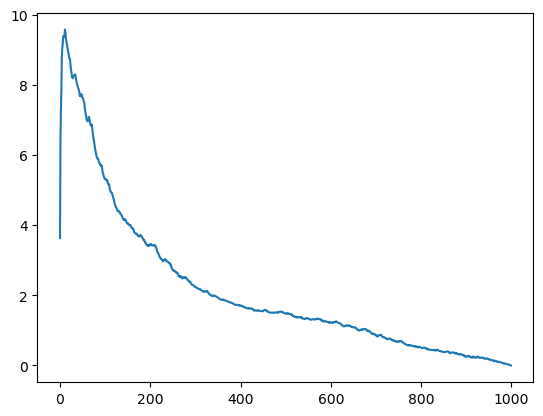

In [429]:
plt.plot(np.array(reg_list['Greedy_linear']).mean(0))

In [423]:
P_t_list = []
for k in trange(10):
    #k = 2
    P_t = np.array([[np.array(act_list['Greedy_linear'])[k,i:(i+1)] in np.argsort(y_list[k])[::-1][:j] 
                     for i in range(1000)] for j in range(1,1000)])

    P_t_list.append(P_t * 1)

100%|████████████████████████████████████████| 10/10 [1:04:34<00:00, 387.49s/it]


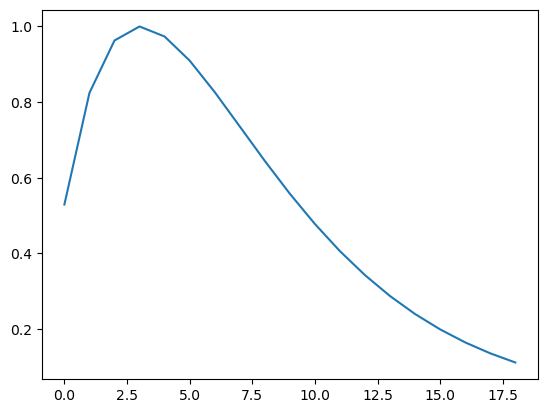

In [382]:
k = 20
z = .5
t = np.arange(1, 20)
plt.plot((t * z / 2) * np.exp(1-t * z / 2))

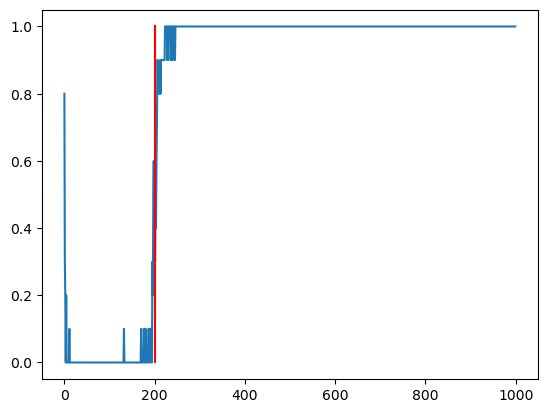

In [424]:
k = 200
plt.plot(1-np.mean(P_t_list, 0)[k,:])
plt.plot(np.array([k,k]), np.array([0,1]), c='r')
#plt.plot((t * z / 2) * np.exp(1-t * z / 2))

In [18]:
np.std(y_list)

NameError: name 'y_list' is not defined

In [17]:
P = 1 - np.mean(P_t_list, 0)
P = np.array([[x, P[x,:(x+1)].sum()] for x in range(999)])
#plt.plot(P[:,1] * 1.76)
plt.plot(np.array(reg_list['Greedy_linear']).mean(0))

NameError: name 'P_t_list' is not defined

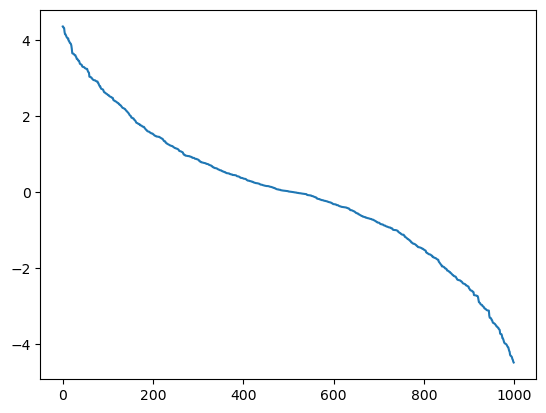

In [449]:
plt.plot(y_list[0][np.argsort(y_list[0])[::-1]])

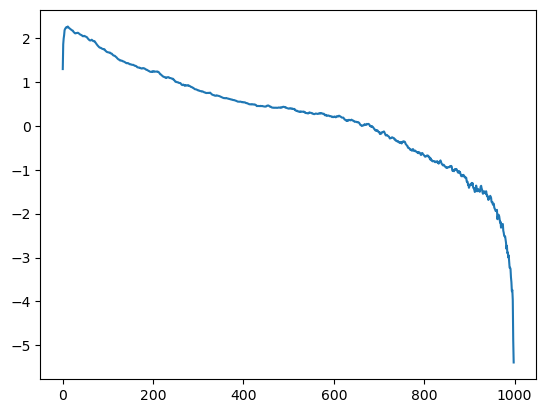

In [441]:
plt.plot(np.log(np.array(reg_list['Greedy_linear']).mean(0)))

<AxesSubplot: >

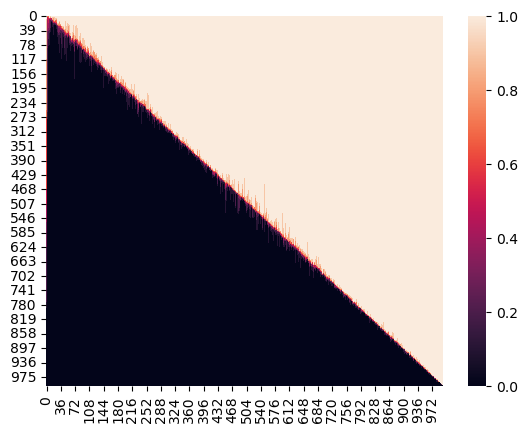

In [470]:
sns.heatmap(1-np.mean(P_t_list,0))

In [477]:
_ = plt.plot(((np.array(reg1_list['TS_linear'])).T).mean(1), label='TS_linear')
_ = plt.fill_between(range(T), (((np.array(reg1_list['TS_linear'])).T).mean(1)-((np.array(reg1_list['TS_linear'])).T).std(1)), 
                     (((np.array(reg1_list['TS_linear'])).T).mean(1)+((np.array(reg1_list['TS_linear'])).T).std(1)), 
                     color = algo_style, alpha=.1)

_ = plt.plot(((np.array(reg1_list['IDS_linear'])).T).mean(1), label='IDS_linear', c='y')
_ = plt.fill_between(range(T), (((np.array(reg1_list['IDS_linear'])).T).mean(1)-((np.array(reg1_list['IDS_linear'])).T).std(1)), 
                     (((np.array(reg1_list['IDS_linear'])).T).mean(1)+((np.array(reg1_list['IDS_linear'])).T).std(1)), 
                     color='y', alpha=.1)

_ = plt.plot((np.array(reg1_list['Greedy_linear'])).T.mean(1), label='Greedy_linear',c='r')
_ = plt.legend()

AxisError: axis 1 is out of bounds for array of dimension 1

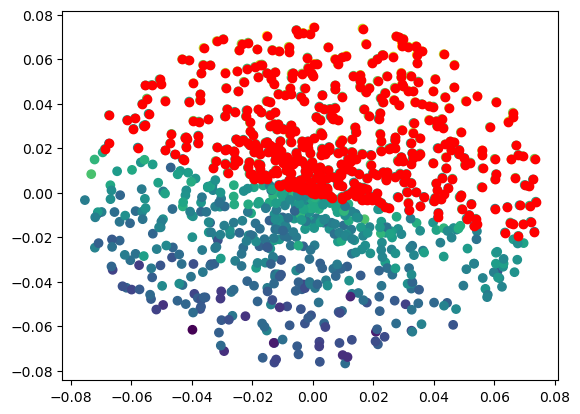

In [476]:
plt.scatter(x[:, 0], x[:, 1], c=y)
n = 500
plt.scatter(x[solver.prob.actions[:n], 0], 
            x[solver.prob.actions[:n], 1], 
            c='r')

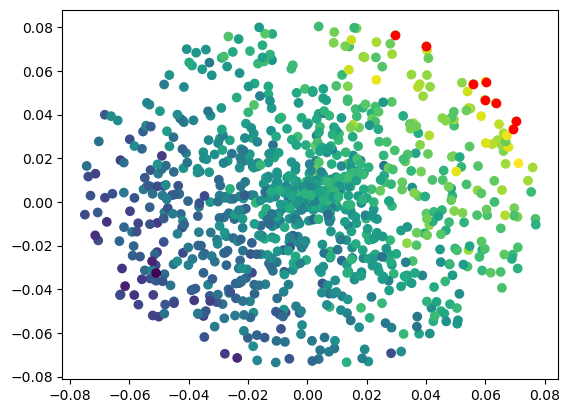

In [184]:
plt.scatter(x[:, 0], x[:, 1], c=y)
n = 8
plt.scatter(x[solver.prob.actions[:n], 0], 
            x[solver.prob.actions[:n], 1], 
            c='r')

In [94]:
from itertools import permutations
from math import factorial
 
# Get all permutations of [1, 2, 3]


In [154]:
y

array([1, 1, 1, 1, 1, 1, 1, 1, 1])

4


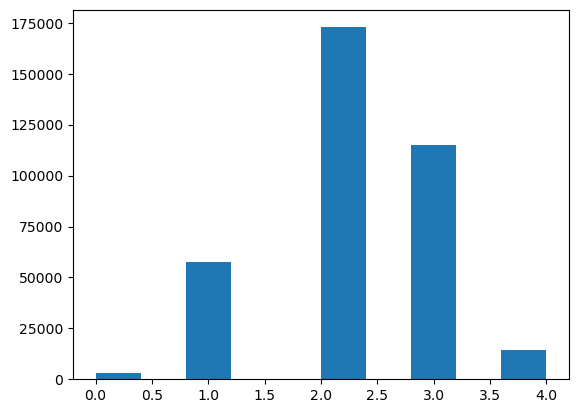

In [361]:
N = 9
rho = 4/9
y = np.array([1]*int(N*rho) + [0]*(N-int(N*rho)))
#y = np.random.binomial(1,.6, N)
y_star = y.copy()
y_star[::-1].sort()

perm = permutations(range(N))
max_reg = np.zeros(factorial(N))
for i, p in enumerate(perm):
    max_reg[i] = (y_star.cumsum()-y[[p]].cumsum()).max()

print(y.sum())
h = plt.hist(max_reg)

In [185]:
def p_max_reg(N,M,K):
    return (factorial(M)*factorial(N-M)) ** 2 / (factorial(M-K) * factorial(K) ** 2 *factorial(N-M-K) * factorial(N))


In [268]:
N = 1000
M = 80

In [269]:
h = np.zeros(81)
for K in range(81):
    h[K] = p_max_reg(N,M,K)

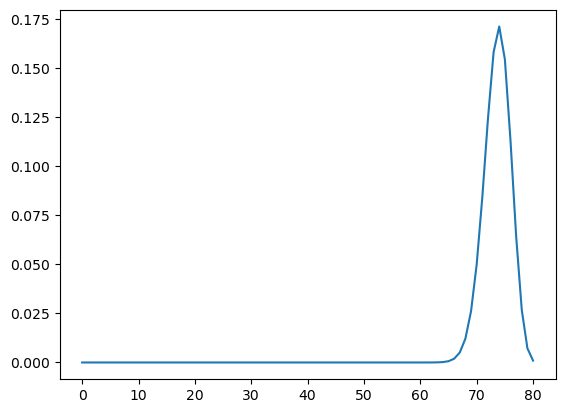

In [271]:

plt.plot(h)

In [196]:
from scipy.stats import hypergeom

In [266]:
[M, n, N] = [1000, 80, 80]
rv = hypergeom(M, n, N)
x = np.arange(0, n+1)
pmf_dogs = rv.pmf(x)

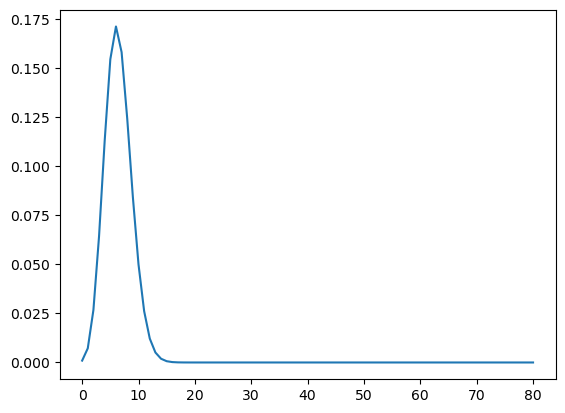

In [272]:
plt.plot(pmf_dogs)

In [264]:
np.round(pmf_dogs * 100)

array([ 0.,  1.,  3.,  6., 11., 15., 17., 16., 12.,  8.,  5.,  3.,  1.,
        1.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
        0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
        0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
        0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
        0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
        0.,  0.,  0.])

In [275]:
np.power(pmf_dogs - h[::-1], 2).sum()

3.5305533945136495e-32

In [281]:
import math

In [284]:
E = np.random.exponential(1,100)
Theta = np.random.rand(100) * 2 * math.pi
Gamma = np.sqrt(E.cumsum()) / (math.pi)
X = np.array([np.cos(Theta) * Gamma, np.sin(Theta) * Gamma]).T

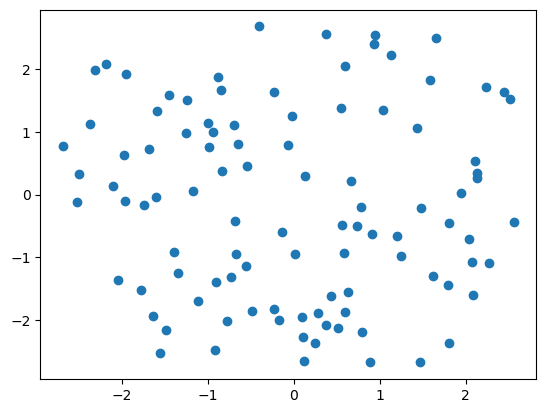

In [295]:
plt.scatter(X[:,0],X[:,1])

In [397]:
factorial(13)/(factorial(10)*factorial(3)) * 3

858.0

In [399]:
factorial(13)/(factorial(11)*factorial(2)) * 11

858.0

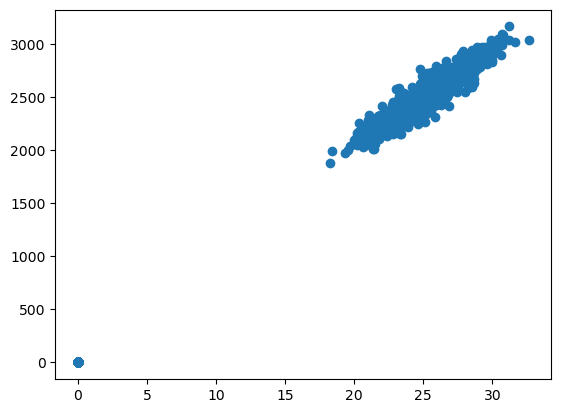

In [103]:
sum_prod = np.zeros(10000)
prod_sum = np.zeros(10000)
for i in range(1000):
    a = (np.random.rand(100))
    b = (np.random.rand(100))
    sum_prod[i] = np.sum(a * b)
    prod_sum[i] = np.sum(a) * np.sum(b)
plt.scatter(sum_prod, prod_sum)

In [73]:
x = np.random.multivariate_normal(np.zeros(2), np.eye(2) + np.ones((2,2)), 100)
theta = np.array([1,-1])
y = x @ theta + np.random.normal(0, 1, 100)

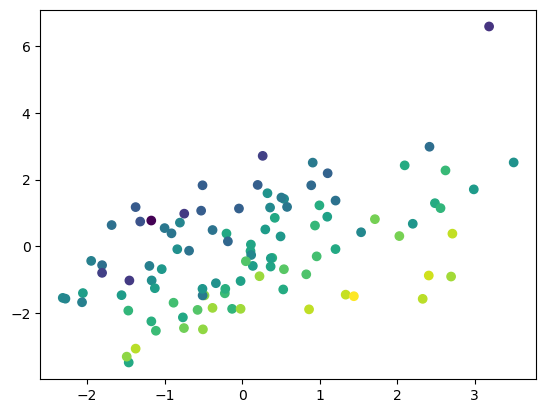

In [74]:
plt.scatter(x[:,0], x[:,1], c=y)

In [77]:
np.linalg.inv(x.T @ x) @ x.T @ y

array([ 1.03532311, -1.07116996])